# Partner insertion on other models

The experiment of `Partner Insertion - Does a Co-operating Motif Raise P(bound).ipynb`, rerun on **hyenadna, dnabert2,
genalm and nt2p5b**. Nothing about the design changes: the **same 34,290 sequences** (`partner_insert/variants.csv`,
built once by that notebook) are read, and only the model and its function direction differ. So for every pair the
question is the same: does inserting the partner's consensus near the motif raise P(bound) more than a random word of
the same length?

* **Readout and direction** are each model's own, exactly as in the cross-model notebooks: the mean hidden state over
  the motif's bases, projected on that model's function direction (`w_all`, `mu`, `sd`). Causal hyenadna reads the
  reverse complement too; masked models do not.
* **Directions are reused, not refitted**, from `fcav_xm/<model>_r<region>/fits/`, in the region the original took the
  motif from (SP1/SP2/SP4/GABPA/ELF1 region 8, FOXA1/FOXA3/STAT1 region 0, ETV1 region 20). A missing one (ETV1 for
  every model; region-0 motifs if that run is not finished) is fitted here with the same estimator and saved to
  `partner_insert_xm/<model>/fits/`, never into `fcav_xm`.
* **Layer**: each model's layer with the best mean AUC over these nine motifs, chosen without looking at the insertion
  result. nt500m is shown at L15, as in the original. Section 3 also draws every layer.
* **Layer-0 check**: for 6-mer and single-base models the motif's own tokens are byte-identical in every pair, so ΔP at
  layer 0 must be 0, as in the original. A BPE tokenizer (dnabert2, genalm) can re-cut the motif's edge tokens when a
  word is inserted a few bases away, so for them layer 0 is reported instead of asserted: a large value there means
  the tokenisation moved, not the model.

Section 2 needs a GPU, Section 3 runs on a CPU.

---
# Section 2 — GPU: directions and projections

In [ ]:
!pip install -q -U "transformers==4.57.6" "tokenizers==0.22.0" "huggingface_hub==0.34.0" "safetensors==0.4.5"
!pip install -q scikit-learn scipy pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.34.0 which is incompatible.
diffusers 0.41.0 requires safetensors>=0.8.0, but you have safetensors 0.4.5 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.34.0 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2.1 Settings, registry and the readout (as in the cross-model notebooks)

In [ ]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json, time, gc, hashlib
import pandas as pd
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from transformers import AutoTokenizer, AutoModel, AutoConfig, AutoModelForMaskedLM, AutoModelForCausalLM

C = json.load(open(f"{WORK_DIR}/config.json"))
REGION = 8                # only supplies the probe windows the readout checks run on
REG = {0: "fcav_pgc_hk_r0", 8: "fcav_pgc_hk", 20: "fcav_pgc_hk_r20"}
SRC = f"{WORK_DIR}/{REG[REGION]}"
XM = f"{WORK_DIR}/fcav_xm"
os.makedirs(XM, exist_ok=True)

# tok_map: how a token index maps to bases.
#   kmer  k  -> token i covers bases [i*k, (i+1)*k)
#   char     -> token i covers base  [i, i+1)
#   offsets  -> ask the tokenizer (fast tokenizers only)
# loader: "hf" = AutoModel/AutoTokenizer; "evo2" = the ArcInstitute package, which has its own tokenizer and
# returns embeddings for NAMED layers instead of an output_hidden_states tuple.
REGISTRY = {
    "nt500m":    dict(hf="InstaDeepAI/nucleotide-transformer-v2-500m-multi-species", tok_map=("kmer", 6),  causal=False, loader="hf", batch=32),
    # NT v1 2.5B: native ESM in transformers, same 6-mer tokenizer as nt500m; every second layer (fitting ~ hidden^2)
    "nt2p5b":    dict(hf="InstaDeepAI/nucleotide-transformer-2.5b-multi-species",   tok_map=("kmer", 6),  causal=False, loader="hf", batch=16, stride=2),
    # NT v2 size series: same data, architecture and tokenizer as nt500m
    "nt100m":    dict(hf="InstaDeepAI/nucleotide-transformer-v2-100m-multi-species", tok_map=("kmer", 6),  causal=False, loader="hf", batch=32),
    "nt250m":    dict(hf="InstaDeepAI/nucleotide-transformer-v2-250m-multi-species", tok_map=("kmer", 6),  causal=False, loader="hf", batch=32),
    "hyenadna":  dict(hf="LongSafari/hyenadna-large-1m-seqlen-hf",                   tok_map=("char",),    causal=True,  loader="hf", batch=32, rc_mode="concat"),
    "dnabert2":  dict(hf="zhihan1996/DNABERT-2-117M",                                tok_map=("offsets",), causal=False, loader="hf", batch=32, out="dnabert2"),
    "genalm":    dict(hf="AIRI-Institute/gena-lm-bert-large-t2t",                    tok_map=("offsets",), causal=False, loader="hf", batch=32),
    "mistraldna":dict(hf="RaphaelMourad/Mistral-DNA-v1-422M-hg38",                   tok_map=("offsets",), causal=True,  loader="hf", batch=32, rc_mode="concat"),
    # Evo 2: byte tokenizer (one token per base) and next-token, so it uses the same `char` map and the same RC pass.
    # 7B is the one that runs in bfloat16 without Transformer Engine; 1B/20B/40B need FP8 and compute capability >= 8.9.
    # `layer_fmt` and `n_blocks` are confirmed by the smoke cell in 2.2 before any fitting.
    "evo2_7b":   dict(hf="arcinstitute/evo2_7b", tok_map=("char",), causal=True, loader="evo2", batch=4,
                      layer_fmt="blocks.{}.mlp.l3", n_blocks=32, stride=4, rc_mode="mean"),
}
# Cheapest first, so the first results arrive early and the one with an unknown cost is last. nt500m is omitted:
# `fcav_pgc_hk_lr` already holds that run and 2.3 only loads it to check this notebook reproduces it.
MODELS = ["hyenadna", "dnabert2", "genalm", "nt2p5b"]
RC_FORCE = None           # None = each model decides from its `causal` flag. True/False overrides it, which
                          # Section 2.3 uses to ask what a second pass does to a MASKED model.
BASE_WEIGHTED = False     # equal weight to every token that touches the motif. With this off, the token set for a
                          # 6-mer model is exactly the legacy [K0, K1), so nt500m reproduces fcav_pgc_hk_lr exactly.
                          # It is a no-op for single-base models (hyenadna, evo2): every token is one base either way.
                          # Turn it on only together with a BPE model, where a token can hold 8 bases and clip 1.
BATCH = 32                # default per forward pass; a registry entry's `batch` overrides it
WLEN, MOFF = C["window_len"], C["motif_offset"]
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # Section 1 runs on CPU
COMP = str.maketrans("ACGTN", "TGCAN")
rc = lambda s: s.translate(COMP)[::-1]
MWJ = json.load(open(f"{SRC}/mpra_windows.json"))
BUILT = sorted(m for m, s in MWJ["status"].items() if s == "built")
print(f"region {REGION}: {len(BUILT)} motifs with sites; models {MODELS}; base-weighted {BASE_WEIGHTED}")

region 8: 31 motifs with sites; models ['hyenadna', 'dnabert2', 'genalm', 'nt2p5b']; base-weighted False


In [ ]:
def load_tokenizer(tag):
    spec = REGISTRY[tag]
    tokz = AutoTokenizer.from_pretrained(spec["hf"], trust_remote_code=True)
    tokz.padding_side = "right"          # several of these default to left (Mistral, HyenaDNA)
    if tokz.pad_token is None:           # Mistral/Llama-style tokenizers ship without one, and padding=True then fails
        tokz.pad_token = tokz.eos_token if tokz.eos_token is not None else tokz.unk_token
    return tokz


def token_bases(spec, n):
    # (n, 2) base interval of each sequence token, for the arithmetic maps
    kind = spec["tok_map"][0]
    if kind == "kmer":
        k = spec["tok_map"][1]
        return np.stack([np.arange(n) * k, (np.arange(n) + 1) * k], 1)
    if kind == "char":
        return np.stack([np.arange(n), np.arange(n) + 1], 1)
    raise RuntimeError("offsets are resolved by the tokenizer, not here")


def encode(tokz, spec, seqs):
    # input_ids (B, T), attention mask (B, T) or None, and per sequence: the POSITIONS of its sequence tokens in
    # input_ids, and the base interval each one covers. Positions are read off the tokenizer and never assumed to
    # start at a fixed offset, so padding side, special tokens and zero-width tokens cannot shift the readout.
    kind = spec["tok_map"][0]
    if spec.get("loader") == "evo2":
        ids = torch.tensor([tokz.tokenize(x) for x in seqs], dtype=torch.int)
        assert ids.shape[1] == len(seqs[0]), f"evo2 tokenised {len(seqs[0])} bp into {ids.shape[1]} tokens"
        n = ids.shape[1]
        return ids, None, [np.arange(n)] * len(seqs), [token_bases(spec, n)] * len(seqs)
    if kind == "offsets":
        assert tokz.is_fast, f"{spec['hf']} has no fast tokenizer, so offset mapping is unavailable"
        enc = tokz(seqs, return_tensors="pt", padding=True, return_offsets_mapping=True)
    else:
        enc = tokz(seqs, return_tensors="pt", padding=True)
    ids = enc["input_ids"]
    am = enc.get("attention_mask")
    if am is None:
        am = (ids != tokz.pad_token_id).long()
    amn = am.numpy()
    pos, spans = [], []
    if kind == "offsets":
        om = enc["offset_mapping"].numpy()
        for b in range(len(seqs)):
            keep = (om[b, :, 1] > om[b, :, 0]) & (amn[b] == 1)
            pos.append(np.flatnonzero(keep))
            spans.append(om[b, keep])
    else:
        for b in range(len(seqs)):
            sp = np.array(tokz.get_special_tokens_mask(ids[b].tolist(), already_has_special_tokens=True))
            p = np.flatnonzero((sp == 0) & (amn[b] == 1))
            pos.append(p)
            spans.append(token_bases(spec, len(p)))
        assert len({len(p) for p in pos}) == 1, (
            f"{spec['hf']}: windows of equal length gave different token counts -- an N splits a 6-mer into "
            f"single bases, which the arithmetic map cannot follow")
    return ids, am, pos, spans


def span_weights(bases, lo, hi):
    # per-token weight for the base interval [lo, hi)
    ov = np.minimum(bases[:, 1], hi) - np.maximum(bases[:, 0], lo)
    ov = np.clip(ov, 0, None).astype(np.float32)
    if not BASE_WEIGHTED:
        ov = (ov > 0).astype(np.float32)
    assert ov.sum() > 0, f"no token covers bases [{lo}, {hi})"
    return ov / ov.sum()


def load_model(tag):
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        from evo2 import Evo2
        return Evo2(spec["hf"].split("/")[-1])
    # Load the class the checkpoint ships its own code for. NT-v2's auto_map has AutoModelForMaskedLM but no
    # AutoModel, so a plain AutoModel falls back to transformers' built-in EsmModel, whose MLP has no gate -- the
    # "8192 vs 4096" size mismatch. AutoModel is still preferred where it exists (DNABERT-2's tuple-returning
    # BertModel is what the dnabert2 branch of hidden_stack expects).
    amap = getattr(AutoConfig.from_pretrained(spec["hf"], trust_remote_code=True), "auto_map", None) or {}
    cls = next((c for k, c in (("AutoModel", AutoModel), ("AutoModelForMaskedLM", AutoModelForMaskedLM),
                               ("AutoModelForCausalLM", AutoModelForCausalLM)) if k in amap), AutoModel)
    mdl = cls.from_pretrained(spec["hf"], trust_remote_code=True).to(DEV).eval()
    # DNABERT-2 ships a triton flash-attention kernel written for an old triton (`tl.dot(..., trans_b=True)`), which
    # current triton refuses to compile. Its code falls back to plain PyTorch attention when that kernel is None, so
    # switch it off in whichever of the model's own modules defines it. A no-op for every other model.
    import sys
    for name in {type(m).__module__ for m in mdl.modules()}:
        mod = sys.modules.get(name)
        if mod is not None and getattr(mod, "flash_attn_qkvpacked_func", None) is not None:
            mod.flash_attn_qkvpacked_func = None
            print(f"{tag}: triton flash-attention disabled in {name.split('.')[-1]}; using PyTorch attention")
    if spec.get("out") == "dnabert2" and getattr(mdl, "pooler", None) is not None:
        # with output_all_encoded_layers=True even the last layer comes back unpadded, (tokens, H), and the pooler's
        # hidden[:, 0] then takes a column instead of the CLS row and crashes. Its output is never used here.
        mdl.pooler = None
    return mdl


@torch.no_grad()
def hidden_stack(tag, model, ids, am):
    # one (layers, T_j, H) float tensor per sequence, whatever the architecture returns
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        names = [spec["layer_fmt"].format(i) for i in SEL[tag]]
        _, emb = model(ids.to(DEV), return_embeddings=True, layer_names=names)
        S = torch.stack([emb[n] for n in names], 1).float()
        return [S[j] for j in range(S.shape[0])]
    if spec.get("out") == "dnabert2":
        # DNABERT-2's remote BertModel swallows output_hidden_states and returns a tuple; every layer needs
        # output_all_encoded_layers=True, and its intermediate layers come back with the padding REMOVED (one flat
        # (tokens, H) block per batch). One unpadded sequence at a time makes each layer that sequence's tokens in
        # order. Right padding (load_tokenizer) keeps the encode positions valid after the pads are cut.
        out = []
        for j in range(ids.shape[0]):
            t = ids[j][am[j].bool()][None].to(DEV)
            layers, _ = model(t, attention_mask=torch.ones_like(t), output_all_encoded_layers=True)
            out.append(torch.stack([x.reshape(t.shape[1], -1) for x in layers], 0).float())
        return out
    kw = {} if spec["causal"] else {"attention_mask": am.to(DEV)}   # a masked model must not attend to the pads;
    hs = model(input_ids=ids.to(DEV), output_hidden_states=True, **kw).hidden_states   # right-padded causal ones can't
    if tag in SEL:                                    # only the layers that will be fitted (stride)
        hs = [hs[i] for i in SEL[tag]]
    S = torch.stack(hs, 1).float()
    return [S[j] for j in range(S.shape[0])]


SEL, DEPTH, LOADED = {}, {}, {}
PROBE = [h["window"] for h in MWJ["hits"][:4]]       # real windows: a repeat like ACGT... tokenises atypically under BPE
for tag in MODELS:
    spec = REGISTRY[tag]
    if spec.get("loader") == "evo2":
        print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  evo2: checked in 2.2, not here")
        continue
    tokz = load_tokenizer(tag)
    ids, am, pos, spans = encode(tokz, spec, PROBE)
    for b in spans:
        assert b[0, 0] == 0 and b[-1, 1] == WLEN, f"{tag}: tokens cover [{b[0, 0]}, {b[-1, 1]}), expected [0, {WLEN})"
        assert (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: token base intervals are not contiguous"
    w = span_weights(spans[0], MOFF, MOFF + 12)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    print(f"{tag:11s} {spec['tok_map'][0]:8s} causal {str(spec['causal']):5s}  "
          f"{min(len(p) for p in pos)}-{max(len(p) for p in pos)} tokens for {WLEN} bp  "
          f"a 12 bp motif touches {int((w > 0).sum())} of them  pad side {tokz.padding_side}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_hyena.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/LongSafari/hyenadna-large-1m-seqlen-hf:
- tokenization_hyena.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


special_tokens_map.json:   0%|          | 0.00/971 [00:00<?, ?B/s]

hyenadna    char     causal True   600-600 tokens for 600 bp  a 12 bp motif touches 12 of them  pad side right


... (7 outputs left out)

tokenizer_config.json:   0%|          | 0.00/129 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/101 [00:00<?, ?B/s]

nt2p5b      kmer     causal False  100-100 tokens for 600 bp  a 12 bp motif touches 2 of them  pad side right


In [ ]:
@torch.no_grad()
def readout(tag, model, seqs, lohi):
    # (n, layers, D): D = hidden, or 2 * hidden for a causal model in concat mode; lohi[i] = the motif's bases
    L = LOADED[tag]
    tokz, spec = L["tokz"], L["spec"]
    use_rc = spec["causal"] if RC_FORCE is None else RC_FORCE
    passes = [(seqs, lohi)]
    if use_rc:
        passes.append(([rc(s) for s in seqs], [(WLEN - b, WLEN - a) for a, b in lohi]))
    bs = spec.get("batch", BATCH)
    parts = []
    for ss, lh in passes:
        out = None
        for i in range(0, len(ss), bs):
            chunk, lhc = ss[i:i + bs], lh[i:i + bs]
            ids, am, pos, spans = encode(tokz, spec, chunk)
            S = hidden_stack(tag, model, ids, am)                     # one (layers, T, H) per sequence
            if out is None:
                out = np.zeros((len(ss), S[0].shape[0], S[0].shape[2]), np.float16)
            for j in range(len(chunk)):
                w = torch.tensor(span_weights(spans[j], *lhc[j]), device=DEV)
                p = torch.tensor(pos[j], device=DEV)
                out[i + j] = (S[j][:, p] * w[None, :, None]).sum(1).half().cpu().numpy()
            del S
        parts.append(out)
    if len(parts) == 1:
        return parts[0]
    if spec.get("rc_mode", "concat") == "mean":
        return ((parts[0].astype(np.float32) + parts[1].astype(np.float32)) / 2).astype(np.float16)
    return np.concatenate(parts, 2)

In [ ]:
EVO2_SMOKE = False        # evo2 is not in MODELS yet; flip this when you want to resolve its API and cost


def prepare(tag):
    # load a model and settle, from one real forward pass, how many layers it returns and that every token position
    # the readout will index exists. The layer ids come from the model, not from a config attribute (HyenaDNA's
    # config has n_layer, not num_hidden_layers; DNABERT-2 returns no embedding-layer output).
    spec = REGISTRY[tag]
    mdl = load_model(tag)
    tokz = mdl.tokenizer if spec.get("loader") == "evo2" else LOADED.get(tag, {}).get("tokz") or load_tokenizer(tag)
    LOADED[tag] = dict(spec=spec, tokz=tokz)
    if spec.get("loader") == "evo2":
        nb = spec["n_blocks"]
        SEL[tag], DEPTH[tag] = sorted(set(range(0, nb, spec.get("stride", 1))) | {nb - 1}), nb - 1
    if spec.get("loader") != "evo2":
        SEL.pop(tag, None)                                # the probe reads every layer
    ids, am, pos, spans = encode(tokz, spec, PROBE[:2])
    S = hidden_stack(tag, mdl, ids, am)
    for j, Sj in enumerate(S):
        assert Sj.ndim == 3 and int(pos[j].max()) < Sj.shape[1], \
            f"{tag}: a (layers, T, H) tensor of shape {tuple(Sj.shape)} cannot hold token position {pos[j].max()}"
        b = spans[j]
        assert b[0, 0] == 0 and b[-1, 1] == WLEN and (b[1:, 0] == b[:-1, 1]).all(), f"{tag}: tokens do not tile"
    nl = S[0].shape[0]
    if spec.get("loader") != "evo2":
        if spec.get("out") == "dnabert2":
            SEL[tag], DEPTH[tag] = list(range(1, nl + 1)), nl
        else:
            SEL[tag], DEPTH[tag] = sorted(set(range(0, nl, spec.get("stride", 1))) | {nl - 1}), nl - 1
    assert spec.get("stride", 1) > 1 or len(SEL[tag]) == nl, f"{tag}: {nl} layers came back, {len(SEL[tag])} expected"
    print(f"{tag}: {nl} layers returned, {len(SEL[tag])} kept (depth {DEPTH[tag]}), hidden {S[0].shape[2]}, "
          f"{len(pos[0])} tokens for {WLEN} bp")
    del S
    return mdl


if EVO2_SMOKE:
    import time as _t
    spec = REGISTRY["evo2_7b"]
    from evo2 import Evo2
    ev = Evo2(spec["hf"].split("/")[-1])
    probe = "ACGT" * (WLEN // 4)
    ids = torch.tensor([ev.tokenizer.tokenize(probe)], dtype=torch.int)
    print(f"600 bp -> {ids.shape[1]} tokens   (must be 600 for the char map to be right)")

    inner = getattr(ev, "model", ev)
    names = [n for n, _ in inner.named_modules()]
    blocks = sorted({int(n.split(".")[1]) for n in names
                     if n.startswith("blocks.") and n.split(".")[1].isdigit()})
    print(f"{len(blocks)} blocks found: {blocks[0]}..{blocks[-1]}   (set n_blocks to {len(blocks)})")
    print("readable names inside the last block:")
    for n in sorted({x for x in names if x.startswith(f"blocks.{blocks[-1]}.")})[:25]:
        print("   ", n)

    want = spec["layer_fmt"].format(blocks[-1])
    assert want in names, f"{want} is not a module; pick one of the names above and set layer_fmt"
    _, emb = ev(ids.to(DEV), return_embeddings=True, layer_names=[want])
    e = emb[want]
    print(f"\n{want}: shape {tuple(e.shape)}  dtype {e.dtype}")
    assert e.shape[1] == ids.shape[1], "that layer does not give one vector per token"

    bs = spec.get("batch", 4)
    sel_names = [spec["layer_fmt"].format(i) for i in range(0, len(blocks), spec.get("stride", 1))]
    batch = torch.tensor([ev.tokenizer.tokenize(probe)] * bs, dtype=torch.int)
    torch.cuda.synchronize(); t0 = _t.time()
    ev(batch.to(DEV), return_embeddings=True, layer_names=sel_names)
    torch.cuda.synchronize(); dt = _t.time() - t0
    per = dt / bs
    print(f"\n{bs} sequences x {len(sel_names)} layers: {dt:.2f}s  ->  {per * 1000:.0f} ms per sequence per pass")
    print(f"with RC that is {2 * per:.3f}s per site; 3000 sites = {2 * per * 3000 / 60:.0f} min for one motif, "
          f"{2 * per * 3000 * 31 / 3600:.1f} h for 31")
    print("\nToo slow? raise stride, or cap the sites per motif. Fix the registry, then add evo2_7b to MODELS.")
    del ev; gc.collect(); torch.cuda.empty_cache()

In [ ]:
# The estimator, copied unchanged from `Function CAV - Strict Labels, PWM-GC-CpG-Matched L2 Logistic,
# Region 8.ipynb`: an L2 logistic path fitted for every layer at once by warm-started Newton steps,
# penalty chosen by inner CV. Verbatim, so a difference between models cannot come from the estimator.
from contextlib import contextmanager
if DEV.type == "cuda":
    torch.backends.cuda.preferred_linalg_library("cusolver")   # batched linalg.solve via cuBLAS fails on some Colab builds
LAMS = torch.logspace(4, -1, 11, device=DEV)      # L2 penalties tried, strongest first (standardised features, summed log-loss)
NEWTON = 15                                       # max Newton steps per penalty
INNER = 3                                         # inner CV folds for the penalty
FAST = True       # speed-up: the Hessian in TF32 and its Cholesky in float32, falling back to the exact float64 path
                  # only for the layers where that fails. The gradient and the loss stay exact float32, so Newton still
                  # converges to the same optimum; only the number of steps it takes can differ. False = the original.


@contextmanager
def _tf32(on):
    old = torch.backends.cuda.matmul.allow_tf32
    torch.backends.cuda.matmul.allow_tf32 = on
    try:
        yield
    finally:
        torch.backends.cuda.matmul.allow_tf32 = old


def logit_path(X, y):
    # L2 logistic regression for every layer at once and every penalty in LAMS (warm-started, strongest first).
    # X: (layers, n, d) standardised; y: (n,) 0/1. Returns W (lams, layers, d + 1) = [weights, intercept].
    nl, n, d = X.shape
    Xa = torch.cat([X, torch.ones(nl, n, 1, device=X.device)], 2)
    pen = torch.ones(d + 1, device=X.device); pen[-1] = 0                # intercept not penalised
    eye = torch.eye(d + 1, device=X.device)
    w = torch.zeros(nl, d + 1, device=X.device)
    w[:, -1] = torch.logit(y.mean().clamp(1e-3, 1 - 1e-3))

    def loss(w, lam):
        z = torch.einsum("lnd,ld->ln", Xa, w)
        return F.binary_cross_entropy_with_logits(z, y.expand_as(z), reduction="none").sum(1) + lam / 2 * (pen * w * w).sum(1)

    out = []
    for lam in LAMS.tolist():
        for _ in range(NEWTON):
            z = torch.einsum("lnd,ld->ln", Xa, w)
            p = torch.sigmoid(z)
            g = torch.einsum("lnd,ln->ld", Xa, p - y) + lam * pen * w
            s_ = p * (1 - p)
            with _tf32(FAST):
                H = (Xa * s_[..., None]).transpose(1, 2) @ Xa + torch.diag(lam * pen + 1e-6)
            # H is SPD in exact arithmetic, but in float32 a weakly penalised, strongly collinear readout can make it
            # numerically indefinite. cholesky_ex does not raise then: it returns a NaN factor and a flag, and the
            # original discarded the flag -- so the step was NaN, and even t = 0 gave w - 0 * NaN = NaN. Factorise in
            # float64, and let a layer whose factorisation still fails stand still instead of turning into NaN.
            if FAST:
                Lc, info = torch.linalg.cholesky_ex(H)
                step = torch.cholesky_solve(g[..., None], Lc)[..., 0]
                bad = (info > 0) | ~torch.isfinite(step).all(1)
                if bad.any():                                                 # exact Hessian, float64, those layers only
                    Xb = Xa[bad].double()
                    Hb = (Xb * s_[bad].double()[..., None]).transpose(1, 2) @ Xb + torch.diag(lam * pen + 1e-6).double()
                    Lb, ib = torch.linalg.cholesky_ex(Hb)
                    sb = torch.cholesky_solve(g[bad].double()[..., None], Lb)[..., 0].float()
                    sb[ib > 0] = 0
                    step[bad] = sb
                    del Xb, Hb, Lb
            else:
                Lc, info = torch.linalg.cholesky_ex(H.double())
                step = torch.cholesky_solve(g.double()[..., None], Lc)[..., 0].float()
                step[info > 0] = 0
            step = torch.where(torch.isfinite(step), step, torch.zeros_like(step))
            ts = torch.tensor([1, .5, .25, .125, 0], device=X.device)
            L = torch.stack([loss(w - t * step, lam) for t in ts])         # (steps, layers); t = 0 keeps w
            L = torch.nan_to_num(L, nan=float("inf"))                         # a NaN loss must never win
            t = ts[L.argmin(0)][:, None]
            w = w - t * step
            if (t * step).abs().max() < 1e-4:
                break
        out.append(w.clone())
    return torch.stack(out)


def bce(Xte, yte, W):
    # held-out summed log-loss of every (penalty, layer); Xte (layers, n, d), W (lams, layers, d + 1)
    z = torch.einsum("lnd,kld->kln", Xte, W[..., :-1]) + W[..., -1:]
    return F.binary_cross_entropy_with_logits(z, yte.expand_as(z), reduction="none").sum(2)


def fit_logit(X, y, seed):
    # penalty per layer by INNER-fold CV log-loss on these sites, then the model on all of them at that penalty.
    # Returns W (layers, d + 1), the chosen penalty index per layer, and the whole path.
    ll = torch.zeros(len(LAMS), X.shape[0], device=X.device)
    yn = y.cpu().numpy()
    for itr, ite in StratifiedKFold(INNER, shuffle=True, random_state=seed).split(np.zeros(len(yn)), yn):
        itr, ite = torch.tensor(itr, device=X.device), torch.tensor(ite, device=X.device)
        ll += bce(X[:, ite], y[ite], logit_path(X[:, itr], y[itr]))
    k = torch.nan_to_num(ll, nan=float("inf")).argmin(0)
    Wp = logit_path(X, y)
    return Wp[k, torch.arange(X.shape[0])], k.cpu().numpy(), Wp


def pct_of(ref, v):
    # percentile of each v among ref (ties count half), 0-100
    ref = np.sort(ref)
    lo, hi = np.searchsorted(ref, v, "left"), np.searchsorted(ref, v, "right")
    return 100 * (lo + hi) / 2 / len(ref)

In [ ]:
def fit_one(X, y, seed, Hh=None):
    # the existing protocol: 5 outer folds, penalty by inner CV, out-of-fold AUC per layer, hit logits per fold
    folds = list(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y))
    Xg = torch.tensor(X, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    yg = torch.tensor(y, dtype=torch.float32, device=DEV)
    Hg = None if Hh is None else torch.tensor(Hh, dtype=torch.float32, device=DEV).transpose(0, 1).contiguous()
    nl = Xg.shape[0]
    oof = np.zeros((len(y), nl), np.float32)
    dk, qk, kk = [], [], []
    for f, (tr, te) in enumerate(folds):
        mu, sd = Xg[:, tr].mean(1, keepdim=True), Xg[:, tr].std(1, keepdim=True) + 1e-6
        W, ki, _ = fit_logit((Xg[:, tr] - mu) / sd, yg[tr], seed + f)
        kk.append(ki)
        oof[te] = (torch.einsum("lnd,ld->ln", (Xg[:, te] - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
        if Hg is not None:
            dh = (torch.einsum("lnd,ld->ln", (Hg - mu) / sd, W[:, :-1]) + W[:, -1:]).cpu().numpy().T
            dk.append(dh); qk.append(1 / (1 + np.exp(-dh)))
    bad = ~np.isfinite(oof).all(0)
    assert not bad.any(), f"non-finite out-of-fold logits at layers {np.flatnonzero(bad).tolist()}"
    auc = np.array([roc_auc_score(y, oof[:, li]) for li in range(nl)])
    mu, sd = Xg.mean(1, keepdim=True), Xg.std(1, keepdim=True) + 1e-6
    Wp = logit_path((Xg - mu) / sd, yg)
    kall = np.median(np.array(kk), 0).round().astype(int)
    W = Wp[torch.tensor(kall, device=DEV), torch.arange(nl, device=DEV)]
    res = dict(auc=auc, oof=oof, cls=y, w_all=W.cpu().numpy(), mu=mu[:, 0].cpu().numpy(), sd=sd[:, 0].cpu().numpy(),
               lam_all=LAMS.cpu().numpy()[kall], layers=np.arange(nl))
    if Hg is not None:
        res["dec_hit"] = np.mean(dk, 0).astype(np.float32)
        res["prob_hit"] = np.mean(qk, 0).astype(np.float32)
    del Xg, Hg, Wp; gc.collect(); torch.cuda.empty_cache()
    return res


LEGACY_LR = {0: "fcav_pgc_hk_lr_r0", 8: "fcav_pgc_hk_lr", 20: "fcav_pgc_hk_lr_r20"}[REGION]
CHECK = []                # nt500m self-check: already passed, and nt2p5b uses the same tokenizer path
CHECK_RC = False          # also fit nt500m WITH a forced RC pass. Off by default: it is d = 2048, so it costs
                          # about four times the rest of this cell, and RC on a masked model is not the design.
if CHECK:
    _bw = BASE_WEIGHTED
    globals()["BASE_WEIGHTED"] = False     # the legacy readout is unweighted; force it here whatever the setting is
    mdl = prepare("nt500m")
    print(f"{'motif':10s} {'sites':>6s} {'legacy best':>12s} {'here RC=off':>12s} {'here RC=on':>11s}   layer of each")
    for m in CHECK:
        J = json.load(open(f"{SRC}/sites/{m}.json"))
        R = J["records"]
        y = np.array([r["cls"] for r in R])
        # With equal weights, the tokens overlapping [MOFF, MOFF + width) ARE the legacy [K0, K1), so this is
        # the old readout exactly -- the AUCs should match to fold noise, not approximately.
        w = int(J.get("width", (J["K1"] - J["K0"]) * 6))
        lohi = [(MOFF, MOFF + w)] * len(R)
        old = np.load(f"{WORK_DIR}/{LEGACY_LR}/fits/{m}.npz")["auc"]
        globals()["RC_FORCE"] = False
        a0 = fit_one(readout("nt500m", mdl, [r["window"] for r in R], lohi), y, C["seed"])["auc"]
        if CHECK_RC:
            globals()["RC_FORCE"] = True
            a1 = fit_one(readout("nt500m", mdl, [r["window"] for r in R], lohi), y, C["seed"])["auc"]
            print(f"{m:10s} {len(y):6d} {old.max():12.3f} {a0.max():12.3f} {a1.max():11.3f}   "
                  f"L{int(old.argmax())} / L{int(a0.argmax())} / L{int(a1.argmax())}")
        else:
            print(f"{m:10s} {len(y):6d} {old.max():12.3f} {a0.max():12.3f} {'-':>11s}   "
                  f"L{int(old.argmax())} / L{int(a0.argmax())}   max |AUC difference| over all layers "
                  f"{np.abs(old - a0).max():.4f}")
    print("\nthe legacy column and the RC=off column must agree to about 0.01; a gap means the span is resolved wrong.")
    print("a large move in the RC=on column on this MASKED model would mean it is not reverse-complement equivariant.")
    print("RC stays OFF for masked models either way: they already see both flanks, so a second pass only doubles the")
    print("feature width and the fitting cost, and makes the numbers incomparable with fcav_pgc_hk_lr.")
    globals()["RC_FORCE"], globals()["BASE_WEIGHTED"] = None, _bw
    del mdl; gc.collect(); torch.cuda.empty_cache()

## 2.2 Every model: find or fit the nine directions, then project every inserted sequence

Resumable per (model, motif): a logits file whose signature matches `variants.csv` is skipped.

In [ ]:
PI, PX = f"{WORK_DIR}/partner_insert", f"{WORK_DIR}/partner_insert_xm"
V = pd.read_csv(f"{PI}/variants.csv", keep_default_na=False)
MJ = json.load(open(f"{PI}/motifs.json"))
# where the original took each motif's sites and direction from: the first region that has both, in this order
REG_SRC = [(8, "fcav_pgc_hk", "fcav_pgc_hk_lr"), (0, "fcav_pgc_hk_r0", "fcav_pgc_hk_lr_r0"),
           (20, "fcav_pgc_hk_r20", "fcav_pgc_hk_lr_r20")]
REGION_OF, SITES_OF = {}, {}
for m in MJ:
    for r, s_, f_ in REG_SRC:
        mw = f"{WORK_DIR}/{s_}/mpra_windows.json"
        if os.path.exists(mw) and json.load(open(mw))["status"].get(m) == "built" and os.path.exists(f"{WORK_DIR}/{f_}/fits/{m}.npz"):
            REGION_OF[m], SITES_OF[m] = r, f"{WORK_DIR}/{s_}/sites/{m}.json"
            break
assert set(REGION_OF) == set(MJ), f"no source region for {set(MJ) - set(REGION_OF)}"
print("motif -> region:", REGION_OF)

USED = json.load(open(f"{PX}/fits_used.json")) if os.path.exists(f"{PX}/fits_used.json") else {}
t_all = time.time()
for tag in MODELS:
    os.makedirs(f"{PX}/{tag}/fits", exist_ok=True); os.makedirs(f"{PX}/{tag}/logits", exist_ok=True)
    todo = []
    for m, g in V.groupby("motif"):
        sig = hashlib.sha1(g[["vid", "seq"]].to_csv(index=False).encode()).hexdigest()
        p = f"{PX}/{tag}/logits/{m}.npz"
        if not (os.path.exists(p) and str(np.load(p)["sig"]) == sig):
            todo.append((m, g, sig))
    print(f"\n=== {tag}: {len(todo)} of {V.motif.nunique()} motifs to project", flush=True)
    if not todo:
        continue
    mdl = prepare(tag)
    for m, g, sig in todo:
        t0 = time.time()
        J = json.load(open(SITES_OF[m]))
        w = int(J.get("width", (J["K1"] - J["K0"]) * 6))
        span = (MOFF, MOFF + w)
        own = f"{XM}/{tag}_r{REGION_OF[m]}/fits/{m}.npz"
        mine = f"{PX}/{tag}/fits/{m}.npz"
        fp = own if os.path.exists(own) else mine
        if not os.path.exists(fp):                                  # fit it here, same estimator, not into fcav_xm
            R = J["records"]
            y = np.array([r["cls"] for r in R])
            X = readout(tag, mdl, [r["window"] for r in R], [span] * len(R))
            assert np.isfinite(X).all(), f"{tag} {m}: non-finite readout"
            res = fit_one(X, y, C["seed"])
            res["layers"] = np.array(SEL[tag])
            np.savez(mine, n_layers=DEPTH[tag], model=tag, region=REGION_OF[m], **res)
            print(f"   {m}: fitted here ({len(y)} sites, best AUC {res['auc'].max():.3f}) [{time.time() - t0:.0f}s]", flush=True)
            del X
        F_ = np.load(fp)
        assert list(F_["layers"]) == list(SEL[tag]), f"{tag} {m}: the fit's layers {list(F_['layers'])} are not {SEL[tag]}"
        mu, sd = torch.tensor(F_["mu"], device=DEV), torch.tensor(F_["sd"], device=DEV)
        W_ = torch.tensor(F_["w_all"], device=DEV)
        seqs = g["seq"].tolist()
        lg = np.zeros((len(seqs), len(SEL[tag])), np.float32)
        for i in range(0, len(seqs), 512):
            X = torch.tensor(readout(tag, mdl, seqs[i:i + 512], [span] * len(seqs[i:i + 512])), device=DEV).float()
            lg[i:i + len(X)] = (torch.einsum("nld,ld->nl", (X - mu) / sd, W_[:, :-1]) + W_[:, -1]).cpu().numpy()
            del X
        np.savez(f"{PX}/{tag}/logits/{m}.npz", vid=g["vid"].values, logit=lg, layers=np.array(SEL[tag]),
                 n_layers=DEPTH[tag], sig=np.array(sig))
        USED.setdefault(tag, {})[m] = fp
        json.dump(USED, open(f"{PX}/fits_used.json", "w"), indent=1)
        print(f"   {m:6s} + {MJ[m]['partner']:6s} {len(seqs):,} seqs  direction from "
              f"{'fcav_xm' if fp == own else 'here'} (region {REGION_OF[m]})  "
              f"[{time.time() - t0:.0f}s, {(time.time() - t_all) / 60:.1f} min]", flush=True)
        gc.collect(); torch.cuda.empty_cache()
    del mdl; gc.collect(); torch.cuda.empty_cache()
print(f"\ndone [{(time.time() - t_all) / 60:.1f} min]")

motif -> region: {'SP2': 8, 'FOXA3': 0, 'STAT1': 0, 'ELF1': 8, 'SP4': 8, 'ETV1': 20, 'FOXA1': 0, 'GABPA': 8, 'SP1': 8}

=== hyenadna: 8 of 9 motifs to project


config.json:   0%|          | 0.00/982 [00:00<?, ?B/s]

configuration_hyena.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/LongSafari/hyenadna-large-1m-seqlen-hf:
- configuration_hyena.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_hyena.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/LongSafari/hyenadna-large-1m-seqlen-hf:
- modeling_hyena.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


... (34 outputs left out)

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Some weights of EsmModel were not initialized from the model checkpoint at InstaDeepAI/nucleotide-transformer-2.5b-multi-species and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


nt2p5b: 33 layers returned, 17 kept (depth 32), hidden 2560, 100 tokens for 600 bp
   ELF1   + SP1    3,810 seqs  direction from fcav_xm (region 8)  [124s, 20.6 min]
   ETV1: fitted here (3824 sites, best AUC 0.843) [206s]
   ETV1   + SP1    3,810 seqs  direction from here (region 20)  [329s, 26.1 min]
   FOXA1  + JUND   3,810 seqs  direction from fcav_xm (region 0)  [124s, 28.2 min]
   FOXA3  + JUND   3,810 seqs  direction from fcav_xm (region 0)  [123s, 30.3 min]
   GABPA  + SP1    3,810 seqs  direction from fcav_xm (region 8)  [123s, 32.3 min]
   SP1    + NFYA   3,810 seqs  direction from fcav_xm (region 8)  [123s, 34.4 min]
   SP2    + NFYA   3,810 seqs  direction from fcav_xm (region 8)  [123s, 36.4 min]
   SP4    + NFYA   3,810 seqs  direction from fcav_xm (region 8)  [123s, 38.5 min]
   STAT1  + Irf1   3,810 seqs  direction from fcav_xm (region 0)  [123s, 40.5 min]

done [40.6 min]


In [ ]:
from google.colab import runtime
runtime.unassign()

---
# Section 3 — CPU: every model side by side

In [1]:
!pip install -q scipy pandas matplotlib

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 3.1 The headline table: partner − random word, real background, 6–24 bp

The original's summary number, for every model: per window the two sides averaged, the median over the near
distances, partner minus the length-matched random word; p is the paired Wilcoxon over (distance, window). The
nt500m column is the original run (L15) and should reproduce its table (SP2+NFYA +0.103 …).

In [3]:
WORK_DIR = "/content/drive/MyDrive/GitHub/Biological-Foundation-Model/Notebooks/EP Pair Evaluation/per_occurrence/motif_token_study"
import os, json
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

PI, PX = f"{WORK_DIR}/partner_insert", f"{WORK_DIR}/partner_insert_xm"
SC, MJ = json.load(open(f"{PI}/config.json")), json.load(open(f"{PI}/motifs.json"))
V = pd.read_csv(f"{PI}/variants.csv", keep_default_na=False).drop(columns=["seq"])
USED = json.load(open(f"{PX}/fits_used.json"))
LEGACY = "nt500m (original)"
LP_FIX = {LEGACY: SC["layer"]}      # the original's layer; every other model: best mean AUC over these motifs
INK = "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK})
pd.set_option("display.width", 250)
NEAR = [d for d in SC["dists"] if d <= 24]

# logits per model: (rows of V, layers) and the layer ids; nt500m from the original run
LG, LAY, NLY, LPM = {}, {}, {}, {}
def _load(tag, d):
    lg, lay, nl = None, None, None
    for m in MJ:
        z = np.load(f"{d}/{m}.npz")
        if lg is None:
            lay = [int(x) for x in z["layers"]]
            nl = int(z["n_layers"]) if "n_layers" in z else len(lay) - 1
            lg = np.full((len(V), len(lay)), np.nan, np.float32)
        lg[z["vid"]] = z["logit"]
    return lg, lay, nl
LG[LEGACY], LAY[LEGACY], NLY[LEGACY] = _load(LEGACY, f"{PI}/logits")
for tag in USED:
    if all(os.path.exists(f"{PX}/{tag}/logits/{m}.npz") for m in MJ):
        LG[tag], LAY[tag], NLY[tag] = _load(tag, f"{PX}/{tag}/logits")
for tag in LG:
    if tag in LP_FIX:
        LPM[tag] = LP_FIX[tag]
    else:
        auc = np.mean([np.load(USED[tag][m])["auc"] for m in MJ], 0)
        LPM[tag] = LAY[tag][int(auc.argmax())]
print("models and the layer used:", {t: f"L{LPM[t]}/{NLY[t]}" for t in LG})

REF = V[V.d == -1].set_index(["motif", "wi", "bg"])["vid"]
S0 = V[V.d > 0].copy()
REFV = REF.loc[list(zip(S0.motif, S0.wi, S0.bg))].values


def dP_all(tag):
    P = 1 / (1 + np.exp(-LG[tag]))
    return P[S0["vid"].values] - P[REFV]            # (insertions, layers)


def near_summary(dp):
    # the original's table: sides averaged per window, median over the near distances, partner - random, paired p
    S = S0.assign(dP=dp)
    W = S.groupby(["motif", "role", "bg", "d", "wi"])["dP"].mean().reset_index()
    W = W[(W.bg == "real") & (W.d.isin(NEAR))]
    out = {}
    for m in MJ:
        a = W[(W.motif == m) & (W.role == "partner")].set_index(["d", "wi"])["dP"]
        b = W[(W.motif == m) & (W.role == "randseq")].set_index(["d", "wi"])["dP"]
        k = a.index.intersection(b.index)
        out[m] = (a.median() - b.median(), stats.wilcoxon(a.loc[k].values - b.loc[k].values).pvalue if len(k) >= 6 else np.nan,
                  W[(W.motif == m) & (W.role == "self")]["dP"].median())
    return out


DP = {tag: dP_all(tag) for tag in LG}
rows = []
for tag in LG:
    li = LAY[tag].index(LPM[tag])
    l0 = np.abs(DP[tag][:, 0]).max() if LAY[tag][0] == 0 else np.nan
    for m, (eff, p, slf) in near_summary(DP[tag][:, li]).items():
        rows.append({"pair": f"{m} + {MJ[m]['partner']}", "model": tag, "partner - random": eff, "p": p, "self": slf})
    print(f"{tag:20s} L{LPM[tag]:<3d} layer-0 |ΔP| max {l0:.1e}" + ("" if np.isnan(l0) or l0 < 1e-5 else
          "   <- not 0: the tokenizer re-cut the motif's tokens for some inserts (BPE); read this model with care"))
R = pd.DataFrame(rows)
R.to_csv(f"{PX}/near_summary_by_model.csv", index=False)
order = R[R.model == LEGACY].sort_values("partner - random", ascending=False)["pair"].tolist()
for col, fmt in (("partner - random", "{:+.3f}"), ("p", "{:.2g}"), ("self", "{:+.3f}")):
    t = R.pivot(index="pair", columns="model", values=col).loc[order, list(LG)]
    print(f"\n--- {col}" + ("   (paired Wilcoxon; 10 windows x near distances)" if col == "p" else
                            "   (a second copy of the motif itself: how far anything can move this direction)" if col == "self" else ""))
    print(t.to_string(formatters={c: fmt.format for c in t.columns}))
t = R.pivot(index="pair", columns="model", values="partner - random").loc[order, list(LG)]
print("\nSpearman of the nine pair effects between models:")
print(t.corr("spearman").to_string(float_format=lambda x: f"{x:+.2f}"))

models and the layer used: {'nt500m (original)': 'L15/29', 'hyenadna': 'L3/9', 'dnabert2': 'L4/12', 'genalm': 'L9/24', 'nt2p5b': 'L12/32'}
nt500m (original)    L15  layer-0 |ΔP| max 6.0e-08
hyenadna             L3   layer-0 |ΔP| max 3.0e-07
dnabert2             L4   layer-0 |ΔP| max nan
genalm               L9   layer-0 |ΔP| max 4.5e-01   <- not 0: the tokenizer re-cut the motif's tokens for some inserts (BPE); read this model with care
nt2p5b               L12  layer-0 |ΔP| max 0.0e+00

--- partner - random
model        nt500m (original) hyenadna dnabert2 genalm nt2p5b
pair                                                          
SP2 + NFYA              +0.103   +0.032   +0.240 +0.166 +0.260
ELF1 + SP1              +0.035   +0.023   +0.020 +0.034 +0.113
STAT1 + Irf1            +0.030   +0.007   +0.041 +0.014 +0.073
SP4 + NFYA              +0.026   +0.007   +0.064 +0.062 +0.051
SP1 + NFYA              +0.011   +0.005   +0.060 +0.018 +0.031
GABPA + SP1             +0.006   +0.002   +0.

## 3.2 Every layer

The same partner − random number at every layer, against relative depth, one panel per pair and one line per model.
The dot on each line is the layer used in 3.1.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: RuntimeWarning: invalid value encountered in scalar divide
  z = (r_plus - mn) / se
/usr/local/lib/python3.13/dist-packages/scipy/stats/_wilcoxon.py:178: Runtim

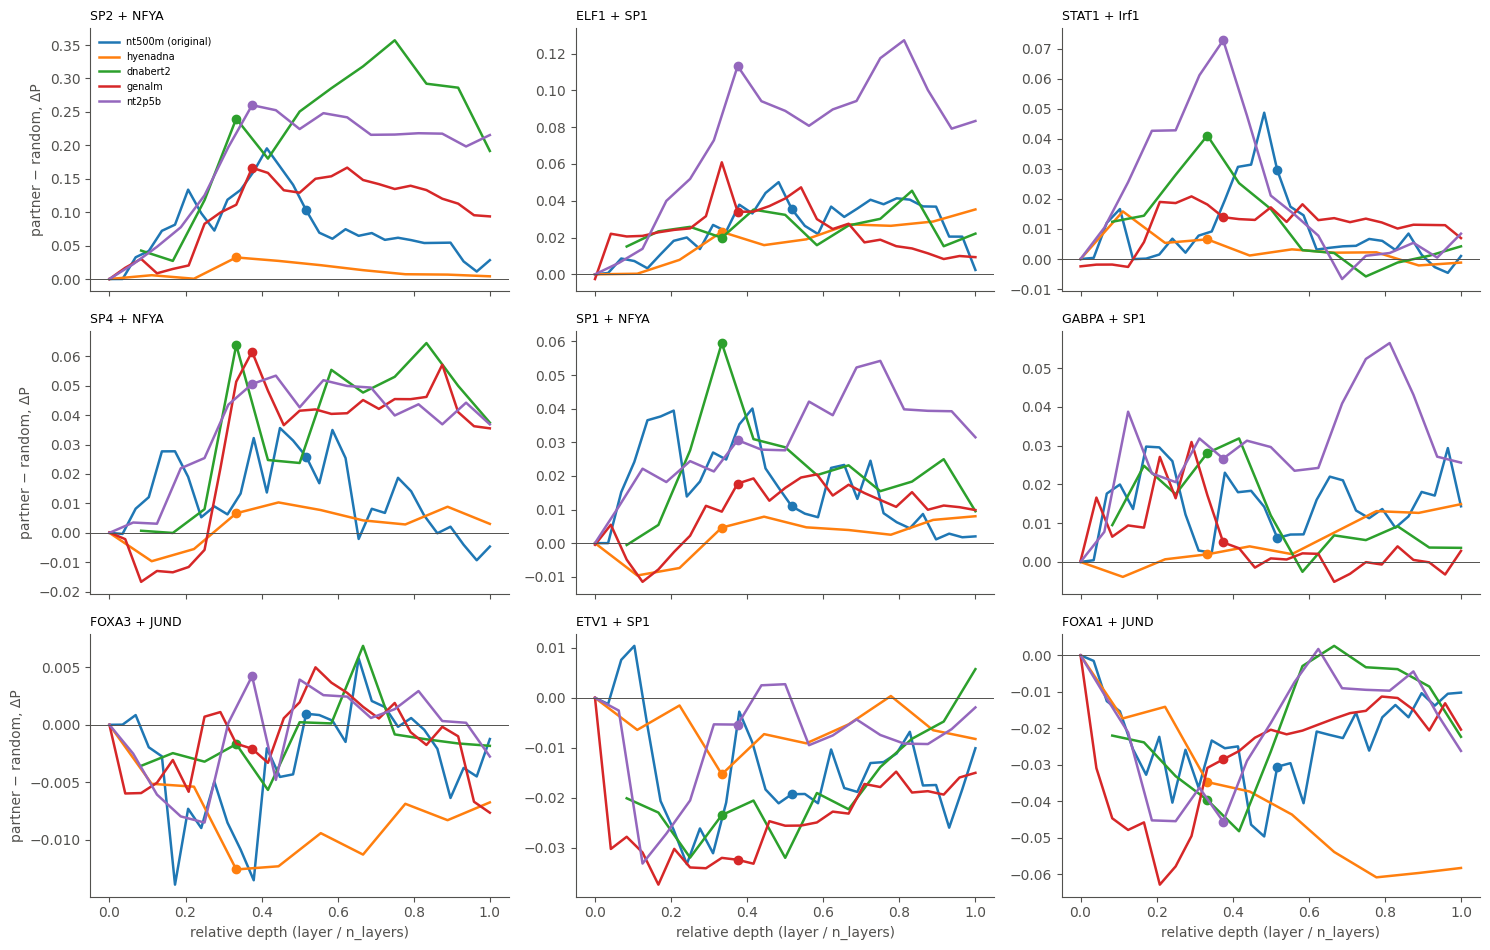

In [4]:
pairs = order
ncol = 3; nrow = int(np.ceil(len(pairs) / ncol))
fig, AX = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.2 * nrow), sharex=True, squeeze=False)
curves = {}
for tag in LG:
    cur = np.array([[near_summary(DP[tag][:, li])[m][0] for m in MJ] for li in range(len(LAY[tag]))])   # (layers, motifs)
    curves[tag] = pd.DataFrame(cur, index=LAY[tag], columns=list(MJ))
for a, pr in zip(AX.ravel(), pairs):
    m = pr.split(" + ")[0]
    for tag in LG:
        c = curves[tag][m]
        ln, = a.plot(np.array(c.index) / NLY[tag], c.values, lw=1.8, label=tag)
        a.plot([LPM[tag] / NLY[tag]], [c.loc[LPM[tag]]], "o", c=ln.get_color(), ms=6)
    a.axhline(0, c=INK, lw=.7)
    a.set_title(pr, loc="left", fontsize=9)
for a in AX.ravel()[len(pairs):]:
    a.axis("off")
for a in AX[-1]:
    a.set_xlabel("relative depth (layer / n_layers)")
for a in AX[:, 0]:
    a.set_ylabel("partner − random, ΔP")
AX[0, 0].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(f"{PX}/partner_minus_random_by_depth.png", dpi=150, bbox_inches="tight"); plt.show()

## 3.3 How the effect changes with insertion distance, every model

Real background, the layer of 3.1; per window and distance the two sides averaged, then the median over the 10 windows.
Three figures, raw ΔP: **partner − random**, **partner** alone, and the **random word** alone (mean of its draws).

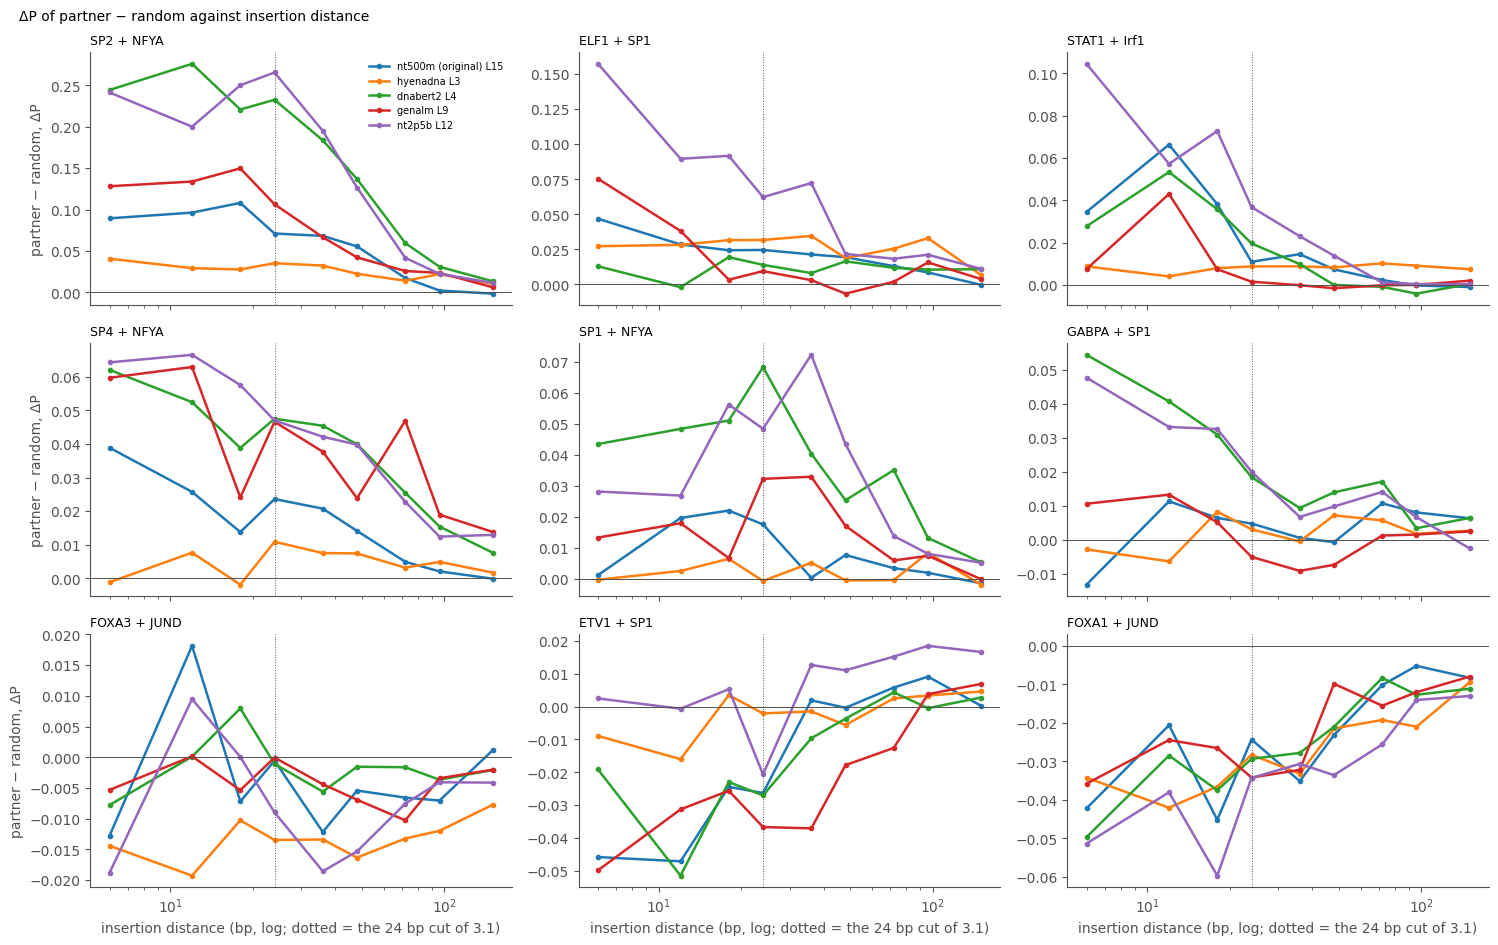

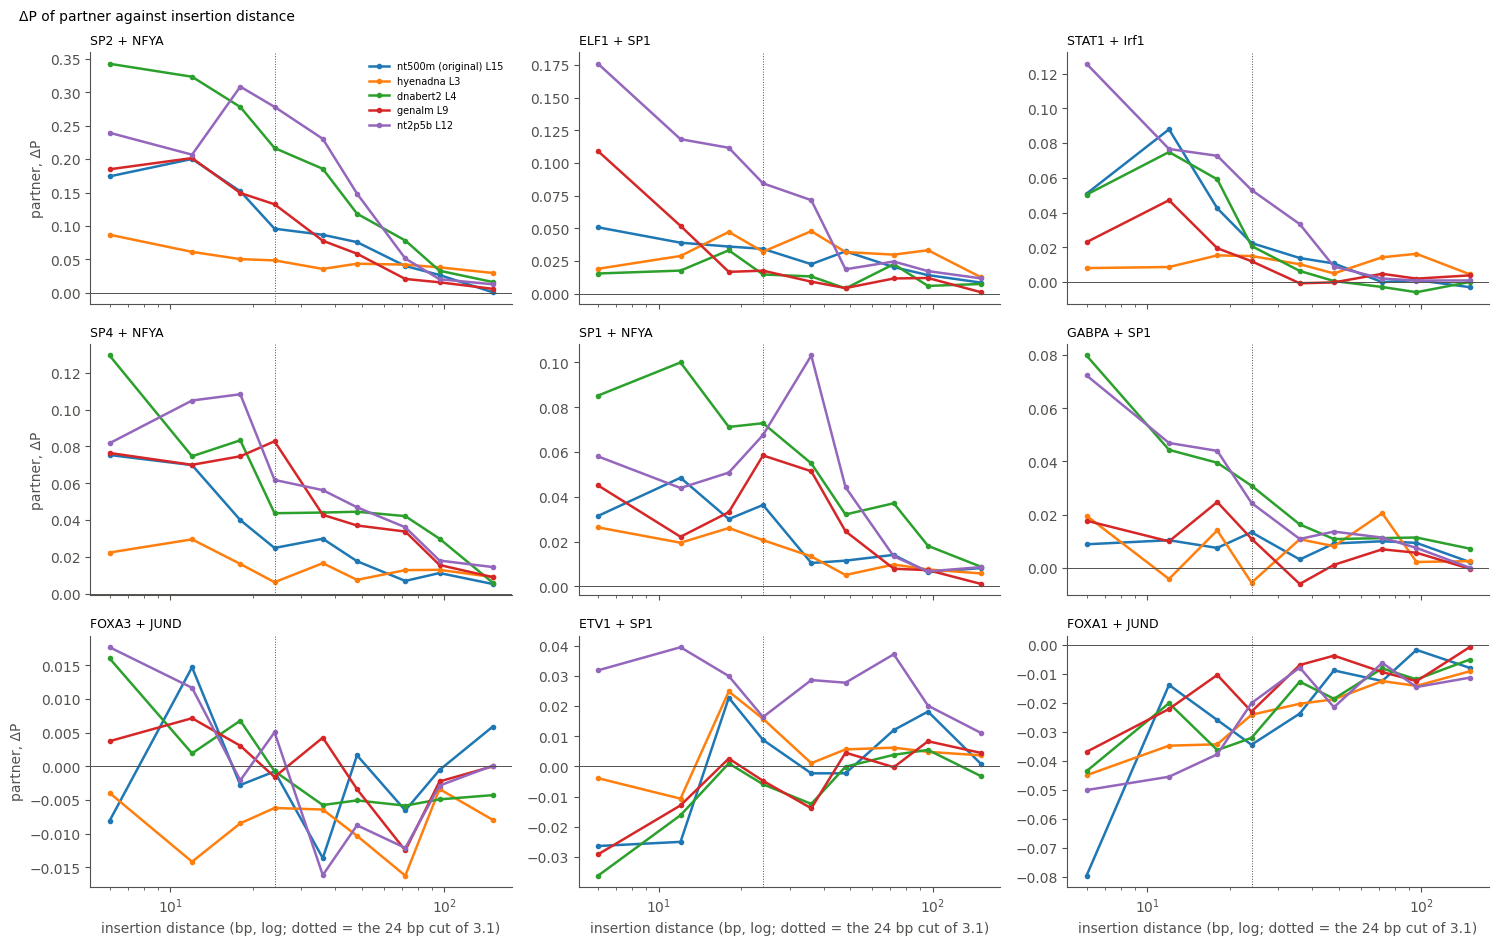

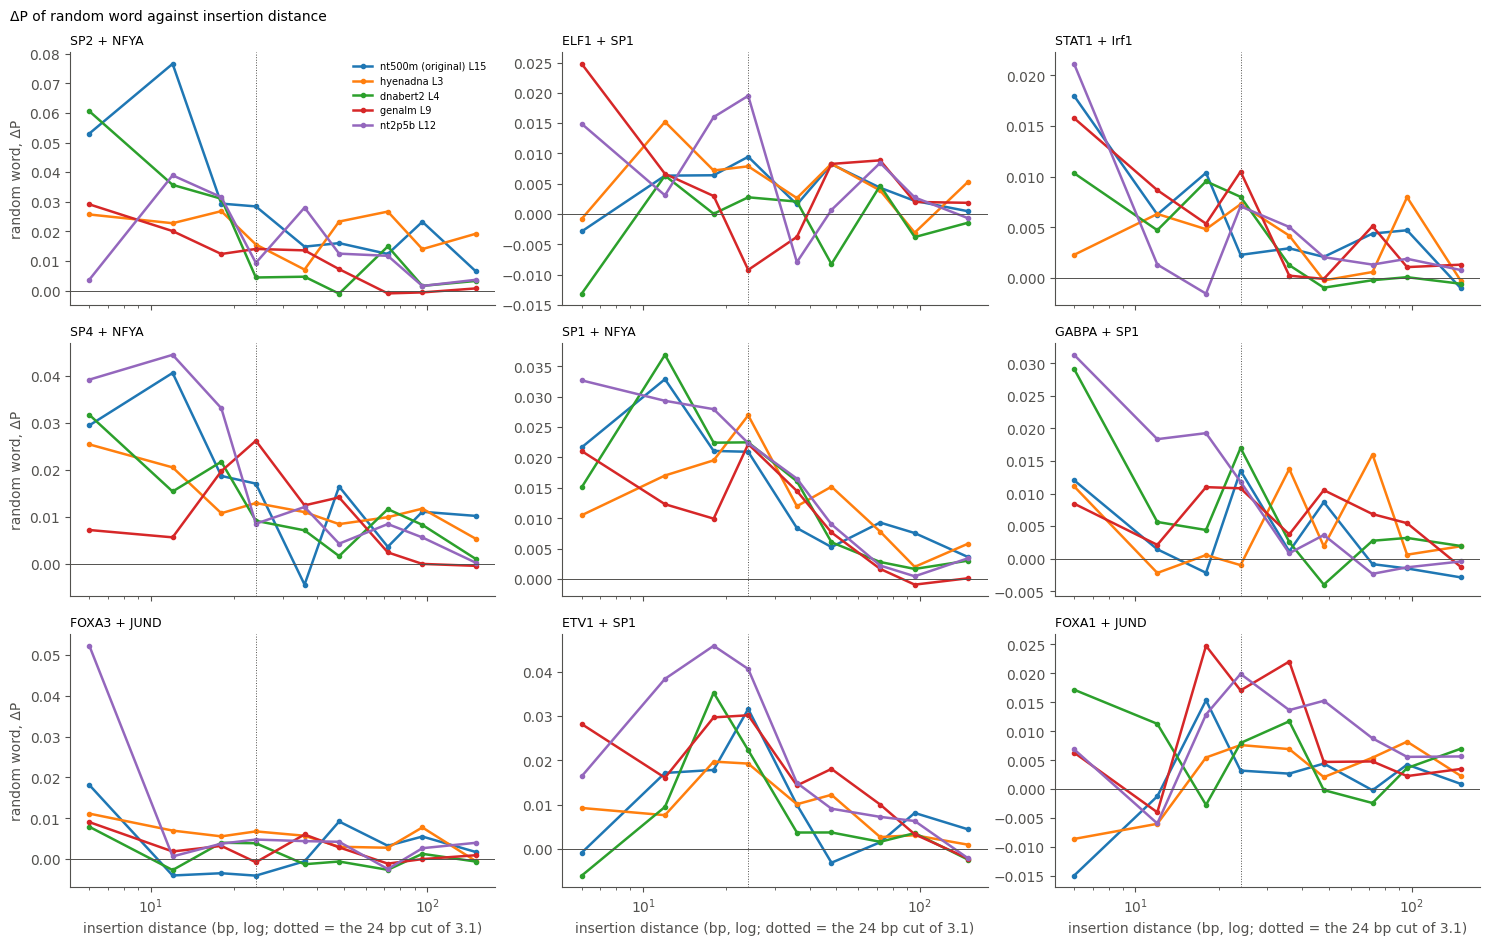

In [5]:
def dist_curve(dp, what):
    # (motif, distance) -> median over windows of the ΔP of `what`, real background
    S = S0.assign(dP=dp)
    W = S[S.bg == "real"].groupby(["motif", "role", "d", "wi"])["dP"].mean().unstack("role")
    v = W["partner"] - W["randseq"] if what == "partner - random" else W[what]
    return v.groupby(["motif", "d"]).median().unstack("d")


for what, name in (("partner - random", "partner − random"), ("partner", "partner"), ("randseq", "random word")):
    fig, AX = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.2 * nrow), sharex=True, squeeze=False)
    for a, pr in zip(AX.ravel(), pairs):
        m = pr.split(" + ")[0]
        for tag in LG:
            c = dist_curve(DP[tag][:, LAY[tag].index(LPM[tag])], what).loc[m]
            a.plot(c.index, c.values, lw=1.8, marker="o", ms=3, label=f"{tag} L{LPM[tag]}")
        a.axhline(0, c=INK, lw=.7)
        a.axvline(24, c=INK, lw=.7, ls=":")
        a.set_xscale("log")
        a.set_title(pr, loc="left", fontsize=9)
    for a in AX.ravel()[len(pairs):]:
        a.axis("off")
    for a in AX[-1]:
        a.set_xlabel("insertion distance (bp, log; dotted = the 24 bp cut of 3.1)")
    for a in AX[:, 0]:
        a.set_ylabel(f"{name}, ΔP")
    AX[0, 0].legend(frameon=False, fontsize=7)
    fig.suptitle(f"ΔP of {name} against insertion distance", x=0.01, ha="left", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{PX}/by_distance_{what.replace(' ', '')}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [6]:
from google.colab import runtime
runtime.unassign()